# Data Analysis & Visualization (DAV) — Lab 12
## AI-Assisted Data Analysis & Visualization: Prompting, Auditing, Critique & Statistical Validation
---
- **Student Roll Number:** `24i-2514`
- **Section:** `DS-5B`
- **Course:** Data Analysis and Visualization (DAV)
- **Scenario:** City General Hospital Quality Department — Evaluating Site A's New Triage System (launched `2025-07-01`) vs. Site B (control, old triage system)
- **Dataset:** `dataset/hospital_wait_times.csv`
---

## Step 0: Imports & Raw Data Loading
We load the raw dataset strictly from its relative path (`dataset/hospital_wait_times.csv`) without modifying anything yet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

raw_df = pd.read_csv("dataset/hospital_wait_times.csv")
print(f"Raw dataset shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
display(raw_df.head())
display(raw_df.sample(5, random_state=42))

Raw dataset shape: 4,225 rows x 10 columns


,visit_id,visit_date,site,department,triage_level,age,wait_minutes,treatment_minutes,satisfaction,triage_system
0,V103691,2025-08-17,Site B,Cardiology,4,88,52.0,28,2.0,Old
1,V100198,2025-05-04,Site A,Cardiology,5,43,87.0,75,4.0,Old
2,V104126,2025-01-17,Site A,Emergency,4,31,102.0,56,NaN,Old
3,V100202,2025-06-30,Site A,Orthopedics,2,29,17.0,98,3.0,Old
4,V104041,2025-08-26,Site A,Radiology,5,68,37.0,20,4.0,New


,visit_id,visit_date,site,department,triage_level,age,wait_minutes,treatment_minutes,satisfaction,triage_system
1505,V101417,2025-06-10,Site A,Pediatrics,4,49,39.0,98,4.0,Old
2342,V101015,2025-11-02,Site B,Emergency,3,39,102.0,27,2.0,Old
3912,V100369,2025-10-09,Site A,Radiology,5,51,10.0,108,4.0,New
4129,V100133,2025-07-24,Site B,Radiology,4,28,18.0,25,3.0,Old
2347,V101296,2025-04-06,Site A,Emergency,3,60,53.0,30,3.0,Old


---
## Task 1: Can We Trust This Data? (Data Reliability & Cleaning Audit)
> **Original Prompt:** *"Report the number of rows, the number of duplicate visit_ids, and the number of missing values in each column. Do not change the data."*

An unguided AI only checks `.shape`, `.duplicated('visit_id').sum()`, and `.isnull().sum()`, concluding the data is "mostly complete." Below we audit **completeness AND validity** across every column (`visit_id`, `visit_date`, `department`, `wait_minutes`, `age`, `satisfaction`, `triage_system`).

In [2]:
# 1. Basic counts (what the original prompt asked)
n_rows = len(raw_df)
n_dup_id = raw_df["visit_id"].duplicated().sum()
n_dup_exact = raw_df.duplicated().sum()
missing_counts = raw_df.isnull().sum()

print("=== Basic Completeness & Duplicate Check ===")
print(f"Total raw rows:        {n_rows:,}")
print(f"Duplicate visit_ids:   {n_dup_id} (exact duplicate rows: {n_dup_exact})")
print("Missing (NaN) counts per column:")
display(missing_counts.to_frame("missing_count").assign(missing_pct=lambda x: (x["missing_count"] / n_rows * 100).round(2)))

# 2. Hidden reliability issues (what the original prompt missed)
iso_dates = pd.to_datetime(raw_df["visit_date"], format="%Y-%m-%d", errors="coerce")
n_non_iso = iso_dates.isna().sum()
parsed_dates = pd.to_datetime(raw_df["visit_date"], format="mixed", dayfirst=True, errors="coerce")

dept_clean = raw_df["department"].astype(str).str.strip().replace({"emergency": "Emergency", "ER": "Emergency"})
n_messy_dept = (raw_df["department"] != dept_clean).sum()

n_neg_wait = (raw_df["wait_minutes"] < 0).sum()
n_sentinel_wait = (raw_df["wait_minutes"] == 999).sum()
n_bad_age = ((raw_df["age"] < 0) | (raw_df["age"] > 120)).sum()

audit_summary = pd.DataFrame([
    {"Issue": "Exact duplicate visit_id rows", "Count": int(n_dup_exact), "Rule / Detail": "visit_id appears twice (exact copy)"},
    {"Issue": "Negative wait_minutes (< 0)", "Count": int(n_neg_wait), "Rule / Detail": f"Range: {raw_df.loc[raw_df['wait_minutes']<0, 'wait_minutes'].min():.0f} to {raw_df.loc[raw_df['wait_minutes']<0, 'wait_minutes'].max():.0f} min"},
    {"Issue": "Sentinel wait_minutes (== 999)", "Count": int(n_sentinel_wait), "Rule / Detail": "Placeholder 999.0 (next highest valid wait is 351.0)"},
    {"Issue": "Impossible age (< 0 or > 120)", "Count": int(n_bad_age), "Rule / Detail": f"Values: {sorted(raw_df.loc[(raw_df['age']<0)|(raw_df['age']>120), 'age'].tolist())}"},
    {"Issue": "Non-ISO visit_date strings", "Count": int(n_non_iso), "Rule / Detail": "DD/MM/YYYY format instead of YYYY-MM-DD (all parseable with dayfirst=True)"},
    {"Issue": "Messy department labels", "Count": int(n_messy_dept), "Rule / Detail": "'Emergency ' (27), 'ER' (26), 'emergency' (19)"},
    {"Issue": "Missing satisfaction scores (NaN)", "Count": int(missing_counts['satisfaction']), "Rule / Detail": "12.24% missing (MNAR: concentrated in long waits)"},
])
print("\n=== Full Reliability Audit Summary ===")
display(audit_summary)

print("\nRaw department value counts:")
print(raw_df["department"].value_counts())

=== Basic Completeness & Duplicate Check ===
Total raw rows:        4,225
Duplicate visit_ids:   25 (exact duplicate rows: 25)
Missing (NaN) counts per column:


,missing_count,missing_pct
visit_id,0,0.00
visit_date,0,0.00
site,0,0.00
department,0,0.00
triage_level,0,0.00
age,0,0.00
wait_minutes,0,0.00
treatment_minutes,0,0.00
satisfaction,517,12.24
triage_system,0,0.00



=== Full Reliability Audit Summary ===


,Issue,Count,Rule / Detail
0,Exact duplicate visit_id rows,25,visit_id appears twice (exact copy)
1,Negative wait_minutes (< 0),10,Range: -57 to -6 min
2,Sentinel wait_minutes (== 999),15,Placeholder 999.0 (next highest valid wait is ...
3,Impossible age (< 0 or > 120),6,"Values: [-1, -1, 150, 230, 230, 230]"
4,Non-ISO visit_date strings,356,DD/MM/YYYY format instead of YYYY-MM-DD (all p...
5,Messy department labels,72,"'Emergency ' (27), 'ER' (26), 'emergency' (19)"
6,Missing satisfaction scores (NaN),517,12.24% missing (MNAR: concentrated in long waits)



Raw department value counts:
department
Emergency      1204
Radiology       894
Pediatrics      767
Orthopedics     651
Cardiology      637
Emergency        27
ER               26
emergency        19
Name: count, dtype: int64


In [3]:
# Create standardized, valid analytical dataset (df_valid)
df = raw_df.copy()
df["visit_date"] = pd.to_datetime(df["visit_date"], format="mixed", dayfirst=True)
df["department"] = df["department"].astype(str).str.strip().replace({"emergency": "Emergency", "ER": "Emergency"})

valid_mask = (
    (~df["visit_id"].duplicated(keep="first"))
    & (df["wait_minutes"] >= 0)
    & (df["wait_minutes"] < 999)
    & (df["age"] >= 0)
    & (df["age"] <= 120)
)
df_valid = df.loc[valid_mask].copy()
df_valid["after_july"] = df_valid["visit_date"] >= pd.Timestamp("2025-07-01")
df_valid["period"] = np.where(df_valid["after_july"], "After (Jul-Dec 2025)", "Before (Jan-Jun 2025)")
df_valid["month"] = df_valid["visit_date"].dt.to_period("M").dt.to_timestamp()

print(f"Raw rows:   {len(raw_df):,}")
print(f"Removed:    {len(raw_df) - len(df_valid):,} (25 duplicates + 10 negative waits + 15 sentinel 999 + 6 invalid ages; non-overlapping)")
print(f"Valid rows: {len(df_valid):,}")

Raw rows:   4,225
Removed:    56 (25 duplicates + 10 negative waits + 15 sentinel 999 + 6 invalid ages; non-overlapping)
Valid rows: 4,169


**Task 1 Answers:**
1. **Is "mostly complete" the same as "reliable"?** No. Nine of ten columns have zero `NaN`s, yet they still contain sentinel codes (`999` min), physically impossible negatives (`-57` min, age `-1`), ages `150`–`230`, `356` `DD/MM/YYYY` dates mixed with ISO dates, `72` inconsistent department spellings (`'Emergency '`, `'ER'`, `'emergency'`), and `25` duplicate visits.
2. **Problems found:** `25` duplicate `visit_id`s; `10` negative `wait_minutes`; `15` sentinel `999.0` `wait_minutes`; `6` out-of-range `age` values (`-1`, `150`, `230`); `356` `DD/MM/YYYY` dates (`dayfirst=True` required); `72` messy `department` strings; `517` missing `satisfaction` scores (`511` among the `4,169` valid rows).
3. **Checks the prompt forgot:** Domain/range bounds (`min`/`max`, negative/sentinel checks), categorical whitespace/casing/synonym checks, date-format parsing checks, and missing-data bias checks.

---
## Task 2: Did the New Triage System Work? (Site A vs. Site B Comparison)
> **Original Prompt:** *"Use only valid rows. Compare mean wait_minutes at Site A before and after 1 July 2025. Show a monthly line chart with axis labels, and state n for each period."*

Comparing Site A to itself before vs. after July 1 captures **temporal association**, not causation. We bring in **Site B** (which retained the old triage system all year) to inspect hospital-wide seasonality and compute the **Difference-in-Differences (DiD)**.

,site,period,n,mean,median,std
0,Site A,After (Jul-Dec 2025),1175,40.86,32.0,32.23
1,Site A,Before (Jan-Jun 2025),1169,54.98,45.0,40.17
2,Site B,After (Jul-Dec 2025),905,46.28,37.0,35.87
3,Site B,Before (Jan-Jun 2025),920,54.09,43.5,40.70


period,After (Jul-Dec 2025),Before (Jan-Jun 2025),Change (After - Before)
site,,,
Site A,40.86,54.98,-14.12
Site B,46.28,54.09,-7.82


Site A Change: -14.12 min
Site B Change: -7.82 min
Difference-in-Differences (Site A - Site B): -6.30 min


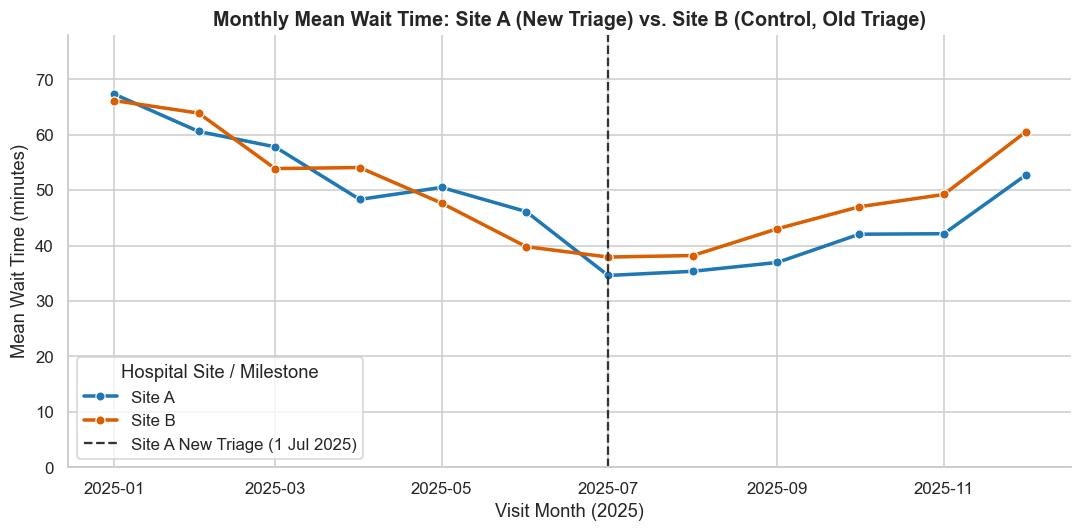

In [4]:
site_summary = (
    df_valid.groupby(["site", "period"])["wait_minutes"]
    .agg(n="count", mean="mean", median="median", std="std")
    .reset_index()
)
display(site_summary.round(2))

piv = site_summary.pivot(index="site", columns="period", values="mean")
piv["Change (After - Before)"] = piv["After (Jul-Dec 2025)"] - piv["Before (Jan-Jun 2025)"]
display(piv.round(2))

did_raw = piv.loc["Site A", "Change (After - Before)"] - piv.loc["Site B", "Change (After - Before)"]
print(f"Site A Change: {piv.loc['Site A', 'Change (After - Before)']:.2f} min")
print(f"Site B Change: {piv.loc['Site B', 'Change (After - Before)']:.2f} min")
print(f"Difference-in-Differences (Site A - Site B): {did_raw:.2f} min")

# Monthly line chart for both Site A and Site B
monthly_site = df_valid.groupby(["month", "site"])["wait_minutes"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
palette = {"Site A": "#1f77b4", "Site B": "#d95f02"}
sns.lineplot(data=monthly_site, x="month", y="wait_minutes", hue="site", marker="o", linewidth=2.3, palette=palette, ax=ax)
ax.axvline(pd.Timestamp("2025-07-01"), color="#333333", linestyle="--", linewidth=1.5, label="Site A New Triage (1 Jul 2025)")
ax.set_ylim(bottom=0, top=78)
ax.set_title("Monthly Mean Wait Time: Site A (New Triage) vs. Site B (Control, Old Triage)", fontsize=13, fontweight="bold")
ax.set_xlabel("Visit Month (2025)")
ax.set_ylabel("Mean Wait Time (minutes)")
ax.legend(title="Hospital Site / Milestone")
plt.tight_layout()
plt.show()

**Task 2 Answers:**
1. **Does Site A's drop prove causation?** No. A single-site pre-post comparison only shows that waits were lower *after* July 1, which conflates the new system with hospital-wide seasonal patterns.
2. **All-2025 seasonality:** Both sites follow a clear U-shaped seasonal curve—peaking in Jan–Feb (`61–67` min), falling to a summer trough in Jul–Aug (`35–38` min), and climbing again in Sep–Dec (`37–61` min). Even without any intervention, H2 begins in the summer low-wait trough.
3. **Comparison site (Site B):** Site B kept the old triage system and still saw its mean wait fall from **54.09 min** ($n = 920$) to **46.28 min** ($n = 905$), a change of **-7.82 min**.
4. **Difference-in-Differences (`Site A change - Site B change`):** $(-14.12) - (-7.82) = \mathbf{-6.30\text{ minutes}}$. Over half of Site A's raw `14.12`-min drop reflects shared seasonal declines seen at Site B; the net unadjusted excess reduction at Site A is `6.30` minutes.

---
## Task 3: Which Departments Improved? (Department Mix Shift / Simpson's Paradox)
> **Original Prompt:** *"Standardise the department labels first and tell me how many rows changed. Then show mean wait_minutes by department before vs after 1 July 2025, for both sites combined, as a grouped bar chart."*

Overall mean wait fell by **11.37 min** (`54.59 -> 43.22`), yet every individual department only dropped between **4.92** and **10.65** min. We expose how a surge in low-wait Radiology volume created a compositional mix illusion.

period,Before (Jan-Jun 2025),After (Jul-Dec 2025),Change (min),Share Before (%),Share After (%),Share Shift (pp)
department,,,,,,
Emergency,73.46,63.16,-10.29,32.36,27.98,-4.38
Orthopedics,61.82,51.17,-10.65,17.47,13.32,-4.16
Cardiology,51.66,45.57,-6.09,15.32,14.90,-0.41
Pediatrics,41.80,35.63,-6.17,18.62,17.45,-1.17
Radiology,26.64,21.72,-4.92,16.23,26.35,10.12


Overall unadjusted mean wait: 54.59 -> 43.22 min (Drop = 11.37 min)
Mix-adjusted post-July mean (using pre-July dept shares): 46.52 min
Within-department drop (constant mix): 8.07 min
Pure department mix-shift contribution: 3.30 min (29.0% of the 11.37 min drop)


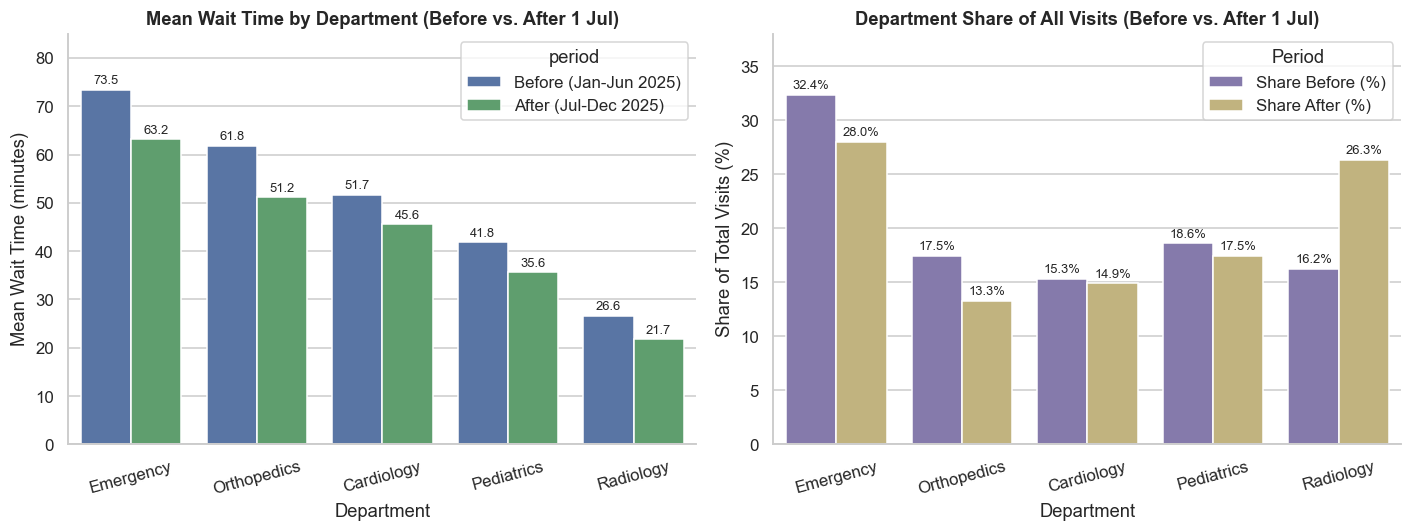

In [5]:
overall_b = df_valid.loc[~df_valid["after_july"], "wait_minutes"].mean()
overall_a = df_valid.loc[df_valid["after_july"], "wait_minutes"].mean()
overall_drop = overall_b - overall_a

dept_means = df_valid.groupby(["department", "period"])["wait_minutes"].mean().unstack()
dept_means = dept_means[["Before (Jan-Jun 2025)", "After (Jul-Dec 2025)"]]
dept_means["Change (min)"] = dept_means["After (Jul-Dec 2025)"] - dept_means["Before (Jan-Jun 2025)"]

shares = pd.crosstab(df_valid["department"], df_valid["period"], normalize="columns") * 100
dept_means["Share Before (%)"] = shares["Before (Jan-Jun 2025)"]
dept_means["Share After (%)"] = shares["After (Jul-Dec 2025)"]
dept_means["Share Shift (pp)"] = dept_means["Share After (%)"] - dept_means["Share Before (%)"]
display(dept_means.sort_values("Before (Jan-Jun 2025)", ascending=False).round(2))

# Constant-mix counterfactual (holding department shares at pre-July weights)
w_before = shares["Before (Jan-Jun 2025)"] / 100.0
mix_adj_after = (dept_means["After (Jul-Dec 2025)"] * w_before).sum()
within_dept_drop = overall_b - mix_adj_after
mix_component = overall_drop - within_dept_drop

print(f"Overall unadjusted mean wait: {overall_b:.2f} -> {overall_a:.2f} min (Drop = {overall_drop:.2f} min)")
print(f"Mix-adjusted post-July mean (using pre-July dept shares): {mix_adj_after:.2f} min")
print(f"Within-department drop (constant mix): {within_dept_drop:.2f} min")
print(f"Pure department mix-shift contribution: {mix_component:.2f} min ({mix_component/overall_drop*100:.1f}% of the 11.37 min drop)")

# Dual panel: Mean Wait by Department + Department Share Shift
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = dept_means.sort_values("Before (Jan-Jun 2025)", ascending=False).index.tolist()
plot_df = df_valid.copy()
sns.barplot(
    data=plot_df, x="department", y="wait_minutes", hue="period",
    order=order, hue_order=["Before (Jan-Jun 2025)", "After (Jul-Dec 2025)"],
    errorbar=None, palette=["#4c72b0", "#55a868"], ax=axes[0]
)
axes[0].set_ylim(bottom=0, top=85)
axes[0].set_title("Mean Wait Time by Department (Before vs. After 1 Jul)", fontweight="bold")
axes[0].set_xlabel("Department")
axes[0].set_ylabel("Mean Wait Time (minutes)")
axes[0].tick_params(axis="x", rotation=15)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f", fontsize=8.5, padding=2)

share_long = (
    dept_means[["Share Before (%)", "Share After (%)"]]
    .reset_index()
    .melt(id_vars="department", var_name="Period", value_name="Visit Share (%)")
)
sns.barplot(data=share_long, x="department", y="Visit Share (%)", hue="Period", order=order, palette=["#8172b3", "#ccb974"], ax=axes[1])
axes[1].set_ylim(bottom=0, top=38)
axes[1].set_title("Department Share of All Visits (Before vs. After 1 Jul)", fontweight="bold")
axes[1].set_xlabel("Department")
axes[1].set_ylabel("Share of Total Visits (%)")
axes[1].tick_params(axis="x", rotation=15)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", fontsize=8.5, padding=2)

plt.tight_layout()
plt.show()

**Task 3 Answers:**
1. **Why is 11.4 min suspicious?** Because every individual department dropped by only **4.92 to 10.65 min**, a weighted average *cannot* drop by `11.37` min unless visit weights shifted toward faster departments (Simpson's Paradox / compositional shift).
2. **Department share shifts:** **Radiology** changed the most, jumping from **16.23% to 26.35% (+10.12 pp)**, while high-wait **Emergency** (`32.36% -> 27.98%`, `-4.38 pp`) and **Orthopedics** (`17.47% -> 13.32%`, `-4.16 pp`) shrank.
3. **Effect of growing Radiology share:** Radiology has the shortest waits (`26.64` min before, `21.72` min after). Giving it a much larger share mechanically drags down the hospital-wide average even without any operational improvement.
4. **Mix-adjusted drop:** Holding department shares fixed at pre-July weights, the drop is **8.07 min** (`54.59 -> 46.52`). Thus, **3.30 min (29.0%)** of the `11.37`-minute overall drop came purely from department mix shift.

---
## Task 4: Does Waiting Reduce Satisfaction? (Missing-Not-At-Random Bias)
> **Original Prompt:** *"Do not fill in missing values. Report mean satisfaction for visits with wait_minutes of 90 or less and for visits over 90, with n for each group. Also report the correlation between wait_minutes and satisfaction."*

Even without imputing missing values, complete-case analysis is biased if missingness correlates with the outcome or exposure.

,total_visits,rated_n,missing_n,missing_pct,mean_satisfaction
wait_group,,,,,
<= 90 min,3664,3375,289,7.89,3.65
> 90 min,505,283,222,43.96,2.28


Overall observed mean satisfaction (n=3,658): 3.54
Pearson correlation (wait_minutes vs satisfaction): r = -0.557

Missing satisfaction (%) by Department:


,missing_%
department,
Cardiology,10.63
Emergency,16.93
Orthopedics,12.77
Pediatrics,9.71
Radiology,8.57


Missing satisfaction (%) by Triage Level:


,missing_%
triage_level,
1,12.43
2,6.89
3,10.76
4,14.51
5,18.32


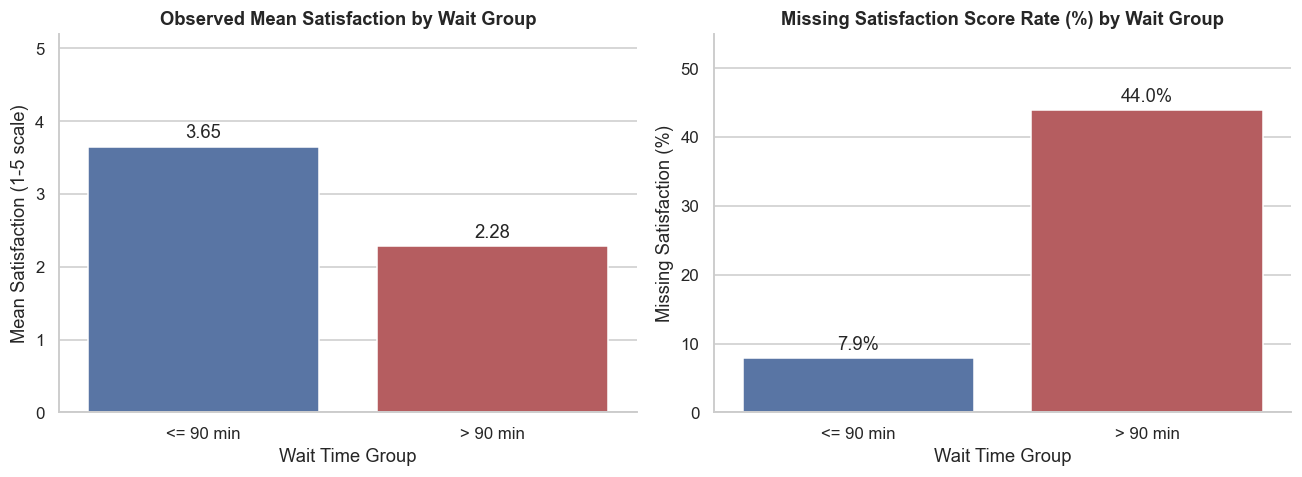

In [6]:
df_valid["wait_group"] = np.where(df_valid["wait_minutes"] <= 90, "<= 90 min", "> 90 min")
overall_sat = df_valid["satisfaction"].mean()
corr_wait_sat = df_valid[["wait_minutes", "satisfaction"]].corr().iloc[0, 1]

sat_audit = (
    df_valid.groupby("wait_group")
    .agg(
        total_visits=("visit_id", "count"),
        rated_n=("satisfaction", "count"),
        missing_n=("satisfaction", lambda s: s.isna().sum()),
        missing_pct=("satisfaction", lambda s: s.isna().mean() * 100),
        mean_satisfaction=("satisfaction", "mean"),
    )
    .loc[["<= 90 min", "> 90 min"]]
)
display(sat_audit.round(2))
print(f"Overall observed mean satisfaction (n={df_valid['satisfaction'].notna().sum():,}): {overall_sat:.2f}")
print(f"Pearson correlation (wait_minutes vs satisfaction): r = {corr_wait_sat:.3f}")

# Check missingness by department and triage level
print("\nMissing satisfaction (%) by Department:")
display((df_valid["satisfaction"].isna().groupby(df_valid["department"]).mean() * 100).round(2).to_frame("missing_%"))
print("Missing satisfaction (%) by Triage Level:")
display((df_valid["satisfaction"].isna().groupby(df_valid["triage_level"]).mean() * 100).round(2).to_frame("missing_%"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=sat_audit.index, y=sat_audit["mean_satisfaction"], hue=sat_audit.index, legend=False, palette=["#4c72b0", "#c44e52"], ax=axes[0])
axes[0].set_ylim(0, 5.2)
axes[0].set_title("Observed Mean Satisfaction by Wait Group", fontweight="bold")
axes[0].set_xlabel("Wait Time Group")
axes[0].set_ylabel("Mean Satisfaction (1-5 scale)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", padding=3)

sns.barplot(x=sat_audit.index, y=sat_audit["missing_pct"], hue=sat_audit.index, legend=False, palette=["#4c72b0", "#c44e52"], ax=axes[1])
axes[1].set_ylim(0, 55)
axes[1].set_title("Missing Satisfaction Score Rate (%) by Wait Group", fontweight="bold")
axes[1].set_xlabel("Wait Time Group")
axes[1].set_ylabel("Missing Satisfaction (%)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

**Task 4 Answers:**
1. **Problem left despite not filling missing values:** Severe **informative missingness (MNAR / non-response bias)**. Complete-case summaries implicitly drop missing rows, skewing the sample toward shorter waits.
2. **Missing % by group:** Only **7.89%** (`289 / 3,664`) of `<= 90 min` visits lack a satisfaction score, compared to **43.96%** (`222 / 505`) of `> 90 min` visits—more than **5.5x higher**!
3. **Who is most likely to have no score?** Long-wait patients (`> 90 min`), particularly in **Emergency (`16.93%` missing)** and low-urgency **Triage Level 5 (`18.32%`) / Level 4 (`14.51%`)**.
4. **Is `3.54` too high or too low? Why can't we be sure?** It is **almost certainly too high** (upwardly biased), because the disproportionately missing `> 90 min` group has a much lower observed mean (`2.28` vs. `3.65`). However, we **cannot be 100% certain** of the exact true population score because unobserved ratings are never seen (we can only bound them via sensitivity scenarios).

---
## Task 5: The Board Headline (Mean vs. Median vs. 90th Percentile)
> **Original Prompt:** *"Make a line chart of monthly mean wait_minutes for Site A and Site B, with a vertical marker at 1 July 2025 and the y-axis starting at 0. Label axes with units. Write a two-sentence headline using association language, not causal language."*

The prompt enforces good graphical integrity and non-causal language, but omits **skewness/distribution metrics** (median and 90th percentile), uncertainty/sample sizes, and case-mix context.

All Valid Rows (n=4,169):
  Mean   = 48.92 min
  Median = 39.00 min
  P90    = 98.00 min
  Skew   = 1.932


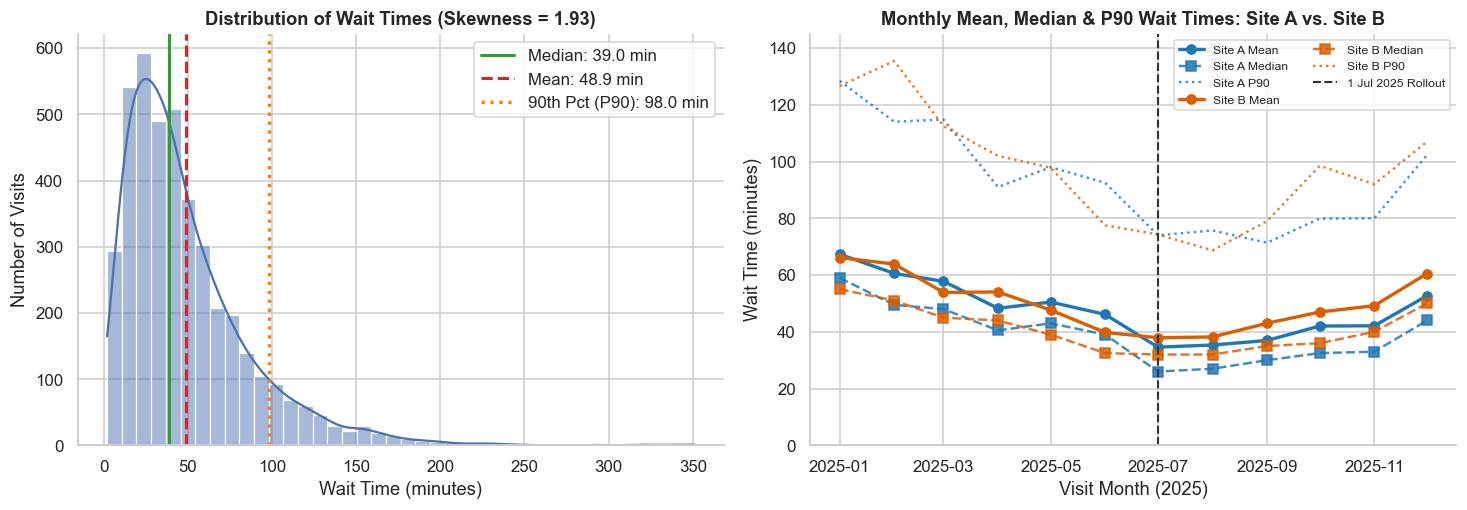

In [7]:
mean_w = df_valid["wait_minutes"].mean()
med_w = df_valid["wait_minutes"].median()
p90_w = df_valid["wait_minutes"].quantile(0.90)
skew_w = df_valid["wait_minutes"].skew()

print(f"All Valid Rows (n={len(df_valid):,}):")
print(f"  Mean   = {mean_w:.2f} min")
print(f"  Median = {med_w:.2f} min")
print(f"  P90    = {p90_w:.2f} min")
print(f"  Skew   = {skew_w:.3f}")

monthly_metrics = (
    df_valid.groupby(["month", "site"])["wait_minutes"]
    .agg(Mean="mean", Median="median", P90=lambda x: np.percentile(x, 90))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel A: Distribution of all valid wait times
sns.histplot(df_valid["wait_minutes"], bins=40, kde=True, color="#4c72b0", ax=axes[0])
axes[0].axvline(med_w, color="#2ca02c", linestyle="-", linewidth=2, label=f"Median: {med_w:.1f} min")
axes[0].axvline(mean_w, color="#d62728", linestyle="--", linewidth=2, label=f"Mean: {mean_w:.1f} min")
axes[0].axvline(p90_w, color="#ff7f0e", linestyle=":", linewidth=2.2, label=f"90th Pct (P90): {p90_w:.1f} min")
axes[0].set_title(f"Distribution of Wait Times (Skewness = {skew_w:.2f})", fontweight="bold")
axes[0].set_xlabel("Wait Time (minutes)")
axes[0].set_ylabel("Number of Visits")
axes[0].legend()

# Panel B: Board-ready monthly Median & P90 alongside Mean
for site_name, color in [("Site A", "#1f77b4"), ("Site B", "#d95f02")]:
    sub = monthly_metrics[monthly_metrics["site"] == site_name]
    axes[1].plot(sub["month"], sub["Mean"], marker="o", linewidth=2.2, color=color, label=f"{site_name} Mean")
    axes[1].plot(sub["month"], sub["Median"], marker="s", linestyle="--", linewidth=1.6, alpha=0.85, color=color, label=f"{site_name} Median")
    axes[1].plot(sub["month"], sub["P90"], linestyle=":", linewidth=1.6, alpha=0.8, color=color, label=f"{site_name} P90")

axes[1].axvline(pd.Timestamp("2025-07-01"), color="#333333", linestyle="--", linewidth=1.4, label="1 Jul 2025 Rollout")
axes[1].set_ylim(bottom=0, top=145)
axes[1].set_title("Monthly Mean, Median & P90 Wait Times: Site A vs. Site B", fontweight="bold")
axes[1].set_xlabel("Visit Month (2025)")
axes[1].set_ylabel("Wait Time (minutes)")
axes[1].legend(ncol=2, fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

**Task 5 Answers:**
1. **What the prompt asks for vs. leaves out:** It specifies Site A vs. Site B, monthly aggregation, the July 1 marker, zero-baseline y-axis, labeled units, and non-causal wording. It leaves out **median** (typical wait), **90th percentile** (worst-case tail), sample sizes/confidence bounds, and case-mix changes.
2. **Summary metrics (all valid rows, $n = 4,169$):** **Mean = 48.92 min**, **Median = 39.00 min**, **90th percentile = 98.00 min** (skewness = `+1.932`). The **median (39.0 min)** best describes a typical patient, while **P90 (98.0 min)** shows the worst waits (slowest 10%).
3. **What the board misses from means alone:** Because waits are strongly right-skewed, a mean-only chart makes typical waits look ~10 minutes longer than the median (`48.9` vs. `39.0` min) while completely hiding that 10% of patients still wait `98+` minutes.

**Board Two-Sentence Headline (Association Language):**
> *Following Site A's July 1 triage update, monthly average wait times declined at both hospitals amid shared seasonal patterns, with Site A showing a larger unadjusted drop (`14.1` min vs. `7.8` min at Site B). However, a typical patient waits `39` minutes overall while `10%` of visits still exceed `98` minutes, and part of Site A's relative decline reflects shifts in department and urgency mix rather than the triage change alone.*

---
## Task 6: Do Older Patients Wait Longer? (Confounding vs. True Drivers)
> **Original Prompt:** *"Use valid rows only. Report the correlation between age and wait_minutes. Report mean wait_minutes and n for age groups 0–17, 18–39, 40–64 and 65+, and show a bar chart with the y-axis starting at 0."*

Pearson correlation (age vs wait_minutes): r = 0.0051


,n,mean,median
age_group,,,
0-17,573,48.80,38.0
18-39,1340,47.91,39.0
40-64,1623,49.38,39.0
65+,633,49.97,40.0


,n,mean_wait,median_wait,mean_age,median_age
triage_level,,,,,
1,169,8.94,8.0,42.40,41.0
2,639,22.30,19.0,41.72,42.0
3,1654,45.40,38.0,41.64,41.0
4,1172,63.29,54.0,41.91,42.0
5,535,72.73,62.0,43.18,44.0


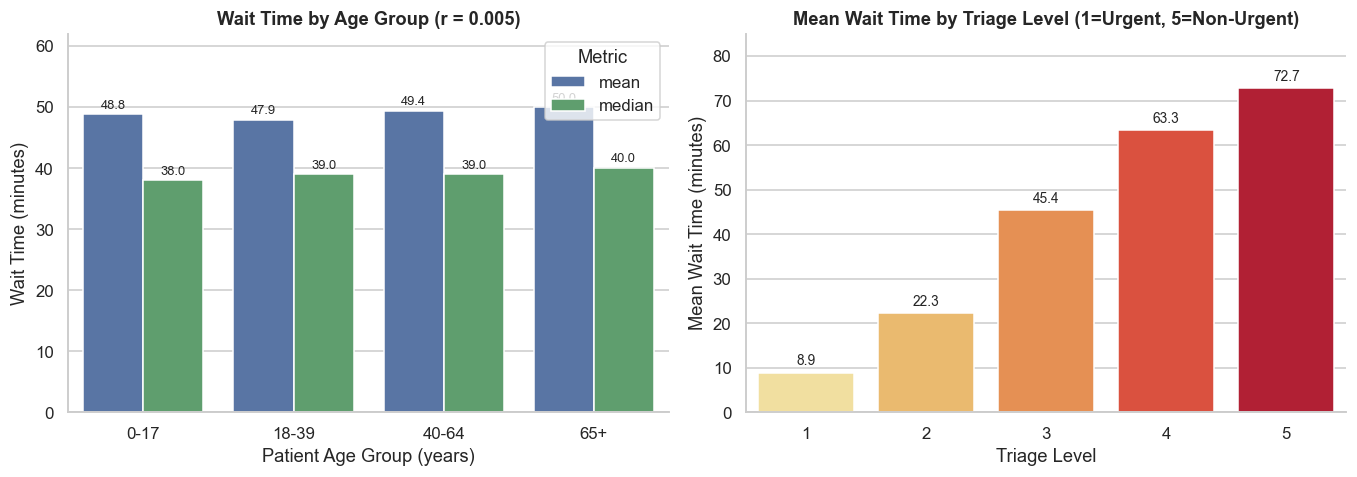

In [8]:
df_valid["age_group"] = pd.cut(df_valid["age"], bins=[-1, 17, 39, 64, 120], labels=["0-17", "18-39", "40-64", "65+"])
r_age_wait = df_valid[["age", "wait_minutes"]].corr().iloc[0, 1]
print(f"Pearson correlation (age vs wait_minutes): r = {r_age_wait:.4f}")

age_tbl = df_valid.groupby("age_group", observed=False)["wait_minutes"].agg(n="count", mean="mean", median="median")
display(age_tbl.round(2))

triage_tbl = df_valid.groupby("triage_level").agg(
    n=("wait_minutes", "count"),
    mean_wait=("wait_minutes", "mean"),
    median_wait=("wait_minutes", "median"),
    mean_age=("age", "mean"),
    median_age=("age", "median"),
)
display(triage_tbl.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

age_long = age_tbl[["mean", "median"]].reset_index().melt(id_vars="age_group", var_name="Metric", value_name="Wait (min)")
sns.barplot(data=age_long, x="age_group", y="Wait (min)", hue="Metric", palette=["#4c72b0", "#55a868"], ax=axes[0])
axes[0].set_ylim(0, 62)
axes[0].set_title(f"Wait Time by Age Group (r = {r_age_wait:.3f})", fontweight="bold")
axes[0].set_xlabel("Patient Age Group (years)")
axes[0].set_ylabel("Wait Time (minutes)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f", fontsize=8.5, padding=2)

sns.barplot(x=triage_tbl.index.astype(str), y=triage_tbl["mean_wait"], hue=triage_tbl.index.astype(str), legend=False, palette="YlOrRd", ax=axes[1])
axes[1].set_ylim(0, 85)
axes[1].set_title("Mean Wait Time by Triage Level (1=Urgent, 5=Non-Urgent)", fontweight="bold")
axes[1].set_xlabel("Triage Level")
axes[1].set_ylabel("Mean Wait Time (minutes)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f", fontsize=9, padding=3)

plt.tight_layout()
plt.show()

**Task 6 Answers:**
1. **Meaningful finding?** No—there is no meaningful age difference (`47.9` to `50.0` min across all four groups, `< 2.1` min spread).
2. **What $r = 0.0051$ and medians show:** Virtually zero linear relationship ($R^2 \approx 0.00003$). Medians are practically identical: `0–17`: **38.0 min**, `18–39`: **39.0 min**, `40–64`: **39.0 min**, `65+`: **40.0 min**.
3. **What actually drives wait time?** **Triage level** (clinical urgency) creates an **8x gradient**: Level 1 = **8.94 min**, Level 2 = **22.30 min**, Level 3 = **45.40 min**, Level 4 = **63.29 min**, Level 5 = **72.73 min** (alongside department bottlenecks).
4. **Is age hiding behind triage?** No. Mean age is virtually flat across all triage levels (`41.64` to `43.18` years; medians `41–44`), and within every triage level $|r(\text{age}, \text{wait})| < 0.09$.
5. **Honest conclusion for the nurse manager:** Elderly patients (`65+`) do **not** wait meaningfully longer than younger adults or children; wait time is governed by clinical triage urgency and department, not patient age.

---
## Task 7: Should We Remove the Outliers? (Skewed Distributions vs. Data Errors)
> **Original Prompt:** *"Use valid rows only. Identify outliers in wait_minutes using the IQR method. Report how many there are and the mean wait with and without them."*

Q1 = 22.0, Q3 = 64.0, IQR = 42.0, Lower Fence = -41.0, Upper Fence = 127.0
IQR-flagged outliers: 183 (4.39% of valid rows)
Mean wait WITH outliers:    48.92 min
Mean wait WITHOUT outliers: 43.65 min
Max valid wait: 351.0 min | Visits > 180 min: 38

Flagged visits by Department:


,flagged_count
department,
Emergency,127
Orthopedics,35
Cardiology,15
Pediatrics,6


Flagged visits by Triage Level:


,flagged_count
triage_level,
3,35
4,89
5,59


period,After (Jul-Dec 2025),Before (Jan-Jun 2025),Change
site,,,
Site A,37.87,48.31,-10.43
Site B,42.19,46.88,-4.69


DiD WITH outliers:    -6.30 min | DiD WITHOUT outliers: -5.74 min


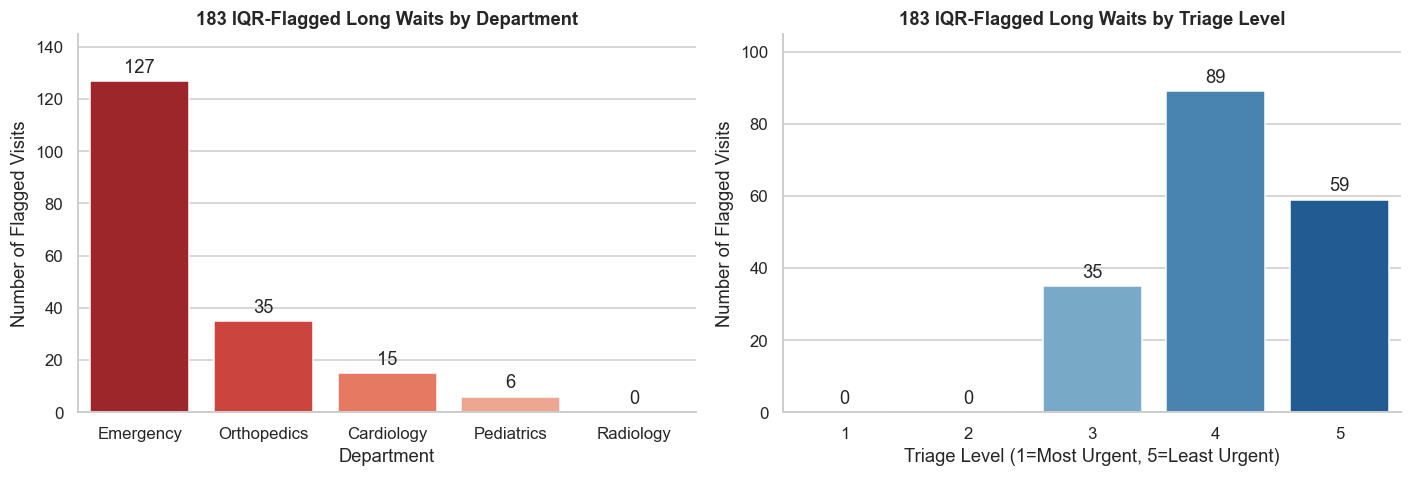

In [9]:
q1, q3 = df_valid["wait_minutes"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_valid["is_iqr_outlier"] = (df_valid["wait_minutes"] < lower_fence) | (df_valid["wait_minutes"] > upper_fence)
outliers_df = df_valid[df_valid["is_iqr_outlier"]]
non_outliers_df = df_valid[~df_valid["is_iqr_outlier"]]

print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}, Lower Fence = {lower_fence:.1f}, Upper Fence = {upper_fence:.1f}")
print(f"IQR-flagged outliers: {len(outliers_df)} ({len(outliers_df)/len(df_valid)*100:.2f}% of valid rows)")
print(f"Mean wait WITH outliers:    {df_valid['wait_minutes'].mean():.2f} min")
print(f"Mean wait WITHOUT outliers: {non_outliers_df['wait_minutes'].mean():.2f} min")
print(f"Max valid wait: {df_valid['wait_minutes'].max():.1f} min | Visits > 180 min: {(df_valid['wait_minutes'] > 180).sum()}")

print("\nFlagged visits by Department:")
display(outliers_df["department"].value_counts().to_frame("flagged_count"))
print("Flagged visits by Triage Level:")
display(outliers_df["triage_level"].value_counts().sort_index().to_frame("flagged_count"))

# Check Task 2 DiD sensitivity without outliers
did_no_out = non_outliers_df.groupby(["site", "period"])["wait_minutes"].mean().unstack()
did_no_out["Change"] = did_no_out["After (Jul-Dec 2025)"] - did_no_out["Before (Jan-Jun 2025)"]
display(did_no_out.round(2))
print(f"DiD WITH outliers:    -6.30 min | DiD WITHOUT outliers: {did_no_out.loc['Site A','Change'] - did_no_out.loc['Site B','Change']:.2f} min")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dept_out = outliers_df["department"].value_counts().reindex(["Emergency", "Orthopedics", "Cardiology", "Pediatrics", "Radiology"], fill_value=0)
sns.barplot(x=dept_out.index, y=dept_out.values, hue=dept_out.index, legend=False, palette="Reds_r", ax=axes[0])
axes[0].set_ylim(0, 145)
axes[0].set_title("183 IQR-Flagged Long Waits by Department", fontweight="bold")
axes[0].set_xlabel("Department")
axes[0].set_ylabel("Number of Flagged Visits")
for c in axes[0].containers:
    axes[0].bar_label(c, padding=3)

triage_out = outliers_df["triage_level"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
sns.barplot(x=triage_out.index.astype(str), y=triage_out.values, hue=triage_out.index.astype(str), legend=False, palette="Blues", ax=axes[1])
axes[1].set_ylim(0, 105)
axes[1].set_title("183 IQR-Flagged Long Waits by Triage Level", fontweight="bold")
axes[1].set_xlabel("Triage Level (1=Most Urgent, 5=Least Urgent)")
axes[1].set_ylabel("Number of Flagged Visits")
for c in axes[1].containers:
    axes[1].bar_label(c, padding=3)

plt.tight_layout()
plt.show()

**Task 7 Answers:**
1. **Where the 183 flagged visits come from:** **127 (69.4%)** are in **Emergency** (`35` Orthopedics, `15` Cardiology, `6` Pediatrics, `0` Radiology), and **100% are in non-urgent/lower-acuity Triage Levels 3–5** (`35` in Level 3, `89` in Level 4, `59` in Level 5; **0** in Levels 1–2).
2. **Data errors or real waits?** Real operational long waits! Real errors look like negative values (`-57`) or sentinel placeholders (`999`), whereas these are plausible low-acuity Emergency delays.
3. **Symmetry & IQR:** `wait_minutes` is strongly **right-skewed** (`skew = +1.932`). Tukey's `1.5 × IQR` rule assumes approximate symmetry; on right-skewed wait times it misclassifies the legitimate heavy right tail as "outliers."
4. **Tail magnitude:** Max valid wait is **351.0 minutes**; **38 visits** waited over 180 minutes (3 hours).
5. **Impact on Task 2:** Removing them reduces both drops (`Site A: -10.43`, `Site B: -4.69`) and yields `DiD = -5.74` min (vs. `-6.30` min), so the relative direction holds—**but deleting them is analytically wrong** because it hides the exact Emergency bottleneck management needs to fix. Report median/P90 alongside mean instead of dropping real waits.

---
## Task 8: Is the Improvement Statistically Real? (DiD, Bootstrap CI & Covariate Adjustment)
> **Original Prompt:** *"Use valid rows only. Test whether Site A’s mean wait_minutes after 1 July 2025 is significantly lower than before. Report the p-value, a 95% confidence interval, and a plain-language conclusion."*

In [10]:
# 1. Naive single-site Welch t-tests for BOTH Site A and Site B (Control)
for s in ["Site A", "Site B"]:
    sub = df_valid[df_valid["site"] == s]
    b = sub.loc[~sub["after_july"], "wait_minutes"]
    a = sub.loc[sub["after_july"], "wait_minutes"]
    t_stat, p_val = stats.ttest_ind(a, b, equal_var=False)
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    print(f"{s} Welch t-test (After - Before): diff = {diff:.2f} min, 95% CI = [{diff - 1.96*se:.2f}, {diff + 1.96*se:.2f}], t = {t_stat:.3f}, p = {p_val:.3e}")

# 2. Unadjusted DiD + 5,000-resample Bootstrap 95% CI
rng = np.random.default_rng(42)
ab = df_valid.loc[(df_valid["site"] == "Site A") & (~df_valid["after_july"]), "wait_minutes"].values
aa = df_valid.loc[(df_valid["site"] == "Site A") & (df_valid["after_july"]), "wait_minutes"].values
bb = df_valid.loc[(df_valid["site"] == "Site B") & (~df_valid["after_july"]), "wait_minutes"].values
ba = df_valid.loc[(df_valid["site"] == "Site B") & (df_valid["after_july"]), "wait_minutes"].values

did_unadj = (aa.mean() - ab.mean()) - (ba.mean() - bb.mean())
boot_diffs = np.array([
    (rng.choice(aa, len(aa), True).mean() - rng.choice(ab, len(ab), True).mean())
    - (rng.choice(ba, len(ba), True).mean() - rng.choice(bb, len(bb), True).mean())
    for _ in range(5000)
])
ci_unadj = np.percentile(boot_diffs, [2.5, 97.5])
print(f"\nUnadjusted DiD: {did_unadj:.2f} min | Bootstrap 95% CI: [{ci_unadj[0]:.2f}, {ci_unadj[1]:.2f}]")

# 3. Urgent share (Triage 1-2) comparison across sites & periods
df_valid["urgent_1_2"] = df_valid["triage_level"].isin([1, 2])
urgent_shares = (df_valid.groupby(["site", "period"])["urgent_1_2"].mean() * 100).unstack()[["Before (Jan-Jun 2025)", "After (Jul-Dec 2025)"]]
urgent_shares["Shift (pp)"] = urgent_shares["After (Jul-Dec 2025)"] - urgent_shares["Before (Jan-Jun 2025)"]
print("\nUrgent Patients (Triage 1-2) Share (%):")
display(urgent_shares.round(2))

# 4. Covariate-Adjusted DiD (OLS controlling for department and triage_level)
X_df = pd.get_dummies(df_valid[["department", "triage_level"]].astype({"triage_level": str}), drop_first=True, dtype=float)
X_df["site_A"] = (df_valid["site"] == "Site A").astype(float)
X_df["after"] = df_valid["after_july"].astype(float)
X_df["did_interaction"] = X_df["site_A"] * X_df["after"]
X_df["const"] = 1.0

X = X_df.values
y = df_valid["wait_minutes"].values
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
did_idx = list(X_df.columns).index("did_interaction")
resid = y - X @ beta
n_obs, p_dim = X.shape
s2 = np.sum(resid ** 2) / (n_obs - p_dim)
cov = s2 * np.linalg.inv(X.T @ X)
se_adj = np.sqrt(cov[did_idx, did_idx])
t_adj = beta[did_idx] / se_adj
p_adj = 2 * (1 - stats.t.cdf(abs(t_adj), df=n_obs - p_dim))
ci_adj = (beta[did_idx] - 1.96 * se_adj, beta[did_idx] + 1.96 * se_adj)

print(f"Covariate-Adjusted DiD (OLS): {beta[did_idx]:.2f} min | SE = {se_adj:.2f} | 95% CI = [{ci_adj[0]:.2f}, {ci_adj[1]:.2f}] | p = {p_adj:.4f}")

Site A Welch t-test (After - Before): diff = -14.12 min, 95% CI = [-17.07, -11.17], t = -9.382, p = 1.542e-20
Site B Welch t-test (After - Before): diff = -7.82 min, 95% CI = [-11.34, -4.30], t = -4.354, p = 1.409e-05



Unadjusted DiD: -6.30 min | Bootstrap 95% CI: [-10.88, -1.83]

Urgent Patients (Triage 1-2) Share (%):


period,Before (Jan-Jun 2025),After (Jul-Dec 2025),Shift (pp)
site,,,
Site A,18.73,21.7,2.97
Site B,20.76,15.8,-4.96


Covariate-Adjusted DiD (OLS): -4.07 min | SE = 1.79 | 95% CI = [-7.58, -0.57] | p = 0.0228


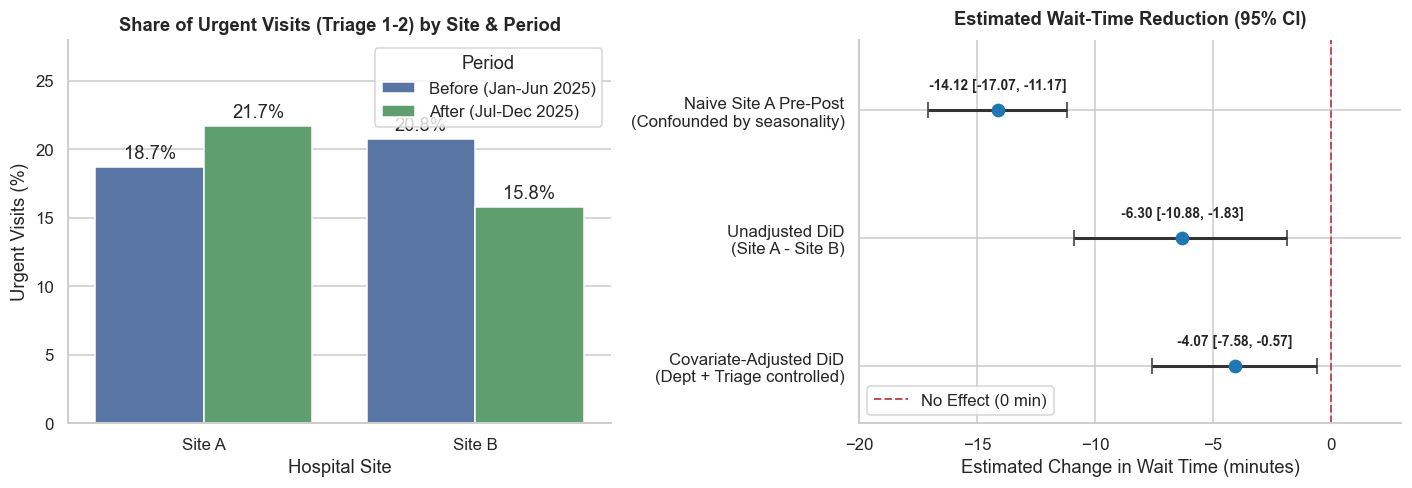

In [11]:
# Visualize Urgent Share Shift + Comparison of Impact Estimates
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Left: Urgent patient share shift
urg_long = urgent_shares[["Before (Jan-Jun 2025)", "After (Jul-Dec 2025)"]].reset_index().melt(
    id_vars="site", var_name="Period", value_name="Urgent Share (%)"
)
sns.barplot(data=urg_long, x="site", y="Urgent Share (%)", hue="Period", palette=["#4c72b0", "#55a868"], ax=axes[0])
axes[0].set_ylim(0, 28)
axes[0].set_title("Share of Urgent Visits (Triage 1-2) by Site & Period", fontweight="bold")
axes[0].set_xlabel("Hospital Site")
axes[0].set_ylabel("Urgent Visits (%)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f%%", padding=3)

# Right: Forest plot comparing naive vs DiD vs Adjusted DiD
est_labels = [
    "Naive Site A Pre-Post\n(Confounded by seasonality)",
    "Unadjusted DiD\n(Site A - Site B)",
    "Covariate-Adjusted DiD\n(Dept + Triage controlled)"
]
ests = [-14.12, did_unadj, beta[did_idx]]
lows = [-17.07, ci_unadj[0], ci_adj[0]]
highs = [-11.17, ci_unadj[1], ci_adj[1]]
y_pos = np.arange(len(est_labels))

axes[1].errorbar(ests, y_pos, xerr=[np.array(ests)-np.array(lows), np.array(highs)-np.array(ests)],
                 fmt="o", color="#1f77b4", ecolor="#333333", elinewidth=2, capsize=5, markersize=8)
axes[1].axvline(0, color="#c44e52", linestyle="--", linewidth=1.3, label="No Effect (0 min)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(est_labels)
axes[1].set_ylim(2.45, -0.55)
axes[1].set_xlim(-20, 3)
axes[1].set_title("Estimated Wait-Time Reduction (95% CI)", fontweight="bold", pad=10)
axes[1].set_xlabel("Estimated Change in Wait Time (minutes)")
for i, (e, lo, hi) in enumerate(zip(ests, lows, highs)):
    axes[1].text(e, i - 0.16, f"{e:.2f} [{lo:.2f}, {hi:.2f}]", ha="center", fontsize=9, fontweight="bold")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

**Task 8 Answers:**
1. **Site B Welch $t$-test:** Site B (which never switched triage systems) also shows a highly significant pre-post drop: **-7.82 min** ($p = 1.41 \times 10^{-5}$). This proves the naive single-site $t$-test at Site A ($p = 1.54 \times 10^{-20}$) only detects shared seasonal/hospital-wide change, not a system effect.
2. **"Statistically significant" $\neq$ "large" or "caused by the system":** With large samples ($n > 1,800$), $p < 0.05$ only rules out pure random sampling fluctuation; it says nothing about practical importance or causal attribution in non-randomized data.
3. **Unadjusted DiD with Bootstrap 95% CI:** **-6.30 min**, 95% bootstrap CI **[-10.88, -1.83] min**.
4. **Urgent-share distortion:** Urgent (Triage 1–2) visits wait much less (`8.9–22.3` min vs. `45–73` min). Post-July, Site A's urgent share **rose** (`18.73% -> 21.70%`, `+2.97 pp`), while Site B's **fell** (`20.76% -> 15.80%`, `-4.96 pp`). Both shifts artificially inflate the unadjusted DiD in Site A's favor.
5. **Covariate-adjusted DiD (department + triage):** Drops by ~35% from `-6.30` min to **-4.07 min** (SE = `1.79`, 95% CI **[-7.58, -0.57]**, $p = 0.0228$).
6. **Board-safe statement for the director:**
   > *"After accounting for hospital-wide seasonal trends using Site B as a comparison and adjusting for changes in department mix and triage urgency, Site A's new triage rollout is associated with an estimated **4.1-minute reduction** in average wait time (95% CI: 0.6 to 7.6 minutes), compared with the unadjusted 14.1-minute raw drop."*